In [ ]:
import torch
from torch.nn import *
import numpy as np

torch.set_default_tensor_type(torch.cuda.FloatTensor)

x = np.loadtxt("../nlpdat/inews/dev.txt", "U", None, "_!_", usecols=(2, 3), encoding="utf-8").view("I").view("2H")[..., 0]
x[:, -1] = ord("。")
x = x[(0x4E00 <= x) & (x <= 0x9FA5)]

M = np.zeros(65536, "I")
np.add.at(M, x, 1)
m = M > 1000
t = M[m]
t = t / t.sum()
print(t @ np.log2(t))
M = m.nonzero()[0]
m = np.full(65536, 65535, "H")
m[M] = np.arange(len(M), dtype="H")
x = m[x]
x = x[x < 65535]

x = dict(np.lib.stride_tricks.as_strided(x[:0].view("P,H"), (len(x) - 4,), (2,)))
t = np.fromiter(x.values(), "H")
x = np.fromiter(x, "P").view("4H")

x = torch.tensor(x.view("h"), dtype=torch.long)
t = torch.tensor(t.view("h"), dtype=torch.long)

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import clear_output


class Embedded(Sequential):
    def __init__(s, c, k, *a):
        super().__init__(*a)
        s.w = Parameter(torch.randn(c, k))

    def forward(s, x):
        return super().forward(functional.embedding(x, s.w).flatten(-2)) @ s.w.T


class Log:
    a = None

    def __call__(s, *x):
        x = [x[None] for x in x]
        s.a = x if s.a is None else [np.concatenate((s, x)) for s, x in zip(s.a, x)]
        for i, x in enumerate(s.a, 1):
            plt.subplot(len(s.a), 1, i).plot(x)
        clear_output(1)
        plt.show()


m = Embedded(len(M), 16, Linear(64, 128), ReLU(1), Linear(128, 16))
o = torch.optim.Adam(m.parameters())
O = torch.optim.lr_scheduler.OneCycleLR(o, 0.03, 10000, pct_start=0.01, div_factor=9, final_div_factor=99)
log = Log()
for i in range(O.total_steps // 100):
    for i in range(100):
        y = m(x)
        l = functional.cross_entropy(y, t)
        l.backward()
        o.step()
        o.zero_grad()
        O.step()
    log(l.detach().cpu(), (y.argmax(1) == t).sum().cpu() / len(t))

8 linear
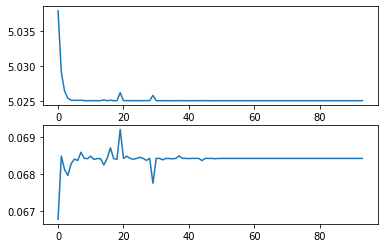